# 12-Month Loan Default Prediction

## Supervisor Progress Update

This notebook presents the first machine-learning results for the Loan Analytics
Platform. The objective is to estimate the probability that a loan will default
within 12 months, using only information available when the loan is issued.

The project uses real anonymised loan records published through the
[Bondora Go & Grow public statistics portal](https://goandgrow.eu/en/public-statistics/).
This is a baseline modelling stage: the results demonstrate the complete workflow,
but the model is not yet ready for production credit decisions.

## Step 1 — Business objective

For each eligible loan, the model produces:

- a **probability of default within 12 months**;
- a binary prediction: **0 = no default**, **1 = default**;
- a simple risk band for reporting: **low**, **medium**, or **high risk**.

The score could later support loan review, portfolio monitoring, and a Power BI
dashboard. It must not yet be interpreted as an automatic approval or rejection
decision.

## Step 2 — Load the saved project artifacts

Model training is implemented in the reusable Python modules under `src/models/`.
This presentation notebook loads the cleaned data, saved evaluation results,
figures, and the selected pipeline without retraining the models.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display
from sklearn.metrics import confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split


def find_project_root(start_path: Path) -> Path:
    '''Locate the repository whether the notebook starts in root or notebooks.'''
    for candidate in [start_path, *start_path.parents]:
        expected_data = candidate / "data" / "processed" / "data_cleaned.csv"
        expected_source = candidate / "src" / "models"
        if expected_data.exists() and expected_source.exists():
            return candidate
    raise FileNotFoundError(
        "Project root not found. Open this notebook from the project repository."
    )


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models.data_preparation import RAW_MODEL_FEATURES, TARGET_COLUMN
from src.models.predict import (
    HIGH_RISK_THRESHOLD,
    LOW_RISK_THRESHOLD,
    load_best_pipeline,
    predict_default_risk,
)

DATA_PATH = PROJECT_ROOT / "data" / "processed" / "data_cleaned.csv"
RESULTS_DIR = PROJECT_ROOT / "reports" / "model_results"
FIGURES_DIR = PROJECT_ROOT / "reports" / "figures"
BEST_MODEL_PATH = PROJECT_ROOT / "models" / "best_default_model.joblib"
METADATA_PATH = RESULTS_DIR / "training_metadata.json"
COMPARISON_PATH = RESULTS_DIR / "model_comparison.csv"

required_artifacts = [
    DATA_PATH,
    BEST_MODEL_PATH,
    METADATA_PATH,
    COMPARISON_PATH,
    FIGURES_DIR / "roc_curve_comparison.png",
    FIGURES_DIR / "precision_recall_curve_comparison.png",
    FIGURES_DIR / "confusion_matrix_gradient_boosting.png",
    FIGURES_DIR / "feature_importance_gradient_boosting.png",
]
missing_artifacts = [path for path in required_artifacts if not path.exists()]
if missing_artifacts:
    missing_text = "\n".join(f"- {path}" for path in missing_artifacts)
    raise FileNotFoundError(
        f"Required project artifacts are missing:\n{missing_text}"
    )

with METADATA_PATH.open(encoding="utf-8") as file:
    metadata = json.load(file)

comparison = pd.read_csv(COMPARISON_PATH)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_colwidth", 100)
plt.style.use("seaborn-v0_8-whitegrid")

display(
    Markdown(
        f"**Artifacts loaded successfully.**  "
        f"Saved selected model: **{metadata['best_model']}**"
    )
)

**Artifacts loaded successfully.**  Saved selected model: **Gradient Boosting**

## Step 3 — Understand the modelling population and target

The target column is `has_default_within_12_months`:

- `0`: no default was observed within the 12-month window;
- `1`: a default was observed within the 12-month window;
- missing: the 12-month outcome is unknown, so the row is excluded from supervised
  training and testing.

Unknown targets are not converted to zero because **unknown does not mean no default**.

,Population,Loans,Share of all records
0,All cleaned records,"737,889",100.00%
1,Records with a known 12-month outcome,"563,510",76.37%
2,Records with an unknown 12-month outcome,"174,379",23.63%


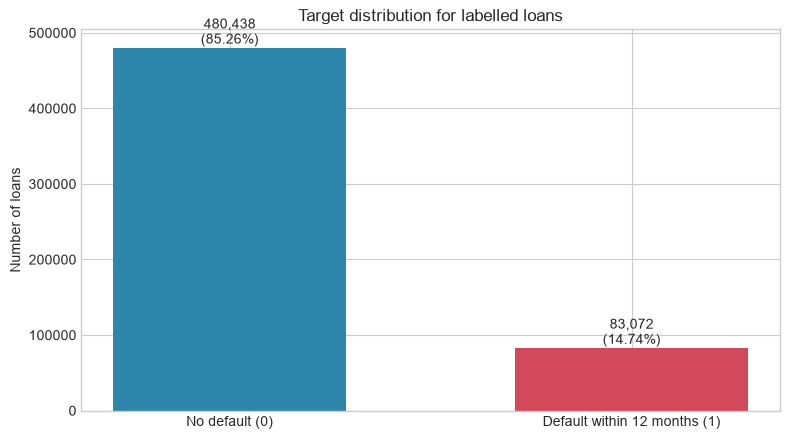

**Key observation:** defaults represent **14.74%** of the labelled loans. This class imbalance is why accuracy alone is not a sufficient evaluation metric: always predicting the majority class would already achieve **85.26%** accuracy.

Unknown targets begin among loans issued on **28 April 2025**; the latest labelled issuance date is **27 April 2025**. This pattern is consistent with recent loans not yet having a complete 12-month observation window.

In [2]:
target_data = pd.read_csv(
    DATA_PATH,
    usecols=[TARGET_COLUMN, "loan_issued_at"],
    low_memory=False,
)
target = target_data[TARGET_COLUMN]
issue_dates = pd.to_datetime(
    target_data["loan_issued_at"],
    errors="coerce",
    format="mixed",
)

total_rows = len(target)
labelled_target = target.dropna().astype("int8")
labelled_rows = len(labelled_target)
unknown_target_rows = int(target.isna().sum())
class_counts = labelled_target.value_counts().sort_index()
default_rate = float(labelled_target.mean())
majority_baseline_accuracy = float(class_counts.max() / labelled_rows)
latest_labelled_date = issue_dates[target.notna()].max()
earliest_unknown_date = issue_dates[target.isna()].min()

population_summary = pd.DataFrame(
    {
        "Population": [
            "All cleaned records",
            "Records with a known 12-month outcome",
            "Records with an unknown 12-month outcome",
        ],
        "Loans": [total_rows, labelled_rows, unknown_target_rows],
        "Share of all records": [
            1.0,
            labelled_rows / total_rows,
            unknown_target_rows / total_rows,
        ],
    }
)

display(
    population_summary.style.format(
        {
            "Loans": "{:,.0f}",
            "Share of all records": "{:.2%}",
        }
    )
)

labels = ["No default (0)", "Default within 12 months (1)"]
values = [int(class_counts.get(0, 0)), int(class_counts.get(1, 0))]
colors = ["#2E86AB", "#D1495B"]

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(labels, values, color=colors, width=0.58)
ax.set_title("Target distribution for labelled loans")
ax.set_ylabel("Number of loans")
ax.ticklabel_format(style="plain", axis="y")

for bar, value in zip(bars, values):
    share = value / labelled_rows
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        value,
        f"{value:,.0f}\n({share:.2%})",
        ha="center",
        va="bottom",
    )

plt.tight_layout()
plt.show()

display(
    Markdown(
        f"**Key observation:** defaults represent **{default_rate:.2%}** of the "
        "labelled loans. This class imbalance is why accuracy alone is not a "
        f"sufficient evaluation metric: always predicting the majority class would "
        f"already achieve **{majority_baseline_accuracy:.2%}** accuracy.\n\n"
        f"Unknown targets begin among loans issued on "
        f"**{earliest_unknown_date:%d %B %Y}**; the latest labelled issuance date is "
        f"**{latest_labelled_date:%d %B %Y}**. This pattern is consistent with recent "
        "loans not yet having a complete 12-month observation window."
    )
)

## Step 4 — Use only leakage-safe input features

The prediction is intended to be made at loan origination. Therefore, the model
must not use information that becomes available after the loan has started.
Repayment totals, balances, arrears, loan status, default dates, and the target
itself were excluded.

The retained inputs are shown below. The issuance timestamp is transformed into
year and month inside the saved pipeline.

In [3]:
feature_descriptions = {
    "country": "Borrower or loan country at origination",
    "loan_issued_at": "Loan issuance timestamp; year and month are derived",
    "issued_amount": "Original amount issued to the borrower",
    "initial_interest_rate": "Interest rate assigned when the loan was issued",
    "initial_loan_duration": "Original contractual loan duration",
    "combined_income": "Declared combined income; may be missing",
    "customer_risk_rating": "Risk grade known at origination; may be missing",
}

feature_table = pd.DataFrame(
    {
        "Raw model feature": RAW_MODEL_FEATURES,
        "Meaning": [feature_descriptions[name] for name in RAW_MODEL_FEATURES],
        "Available at origination": "Yes",
    }
)
display(feature_table)

excluded_groups = pd.DataFrame(
    {
        "Excluded information": [
            "Identifiers",
            "Current loan status and default outcome",
            "Payments, balances, and fees",
            "Arrears and default timing",
            "Early-repayment and later activity",
        ],
        "Reason": [
            "No predictive business meaning",
            "Direct target leakage",
            "Only known after origination",
            "Only known after repayment problems begin",
            "Only known after the loan has started",
        ],
    }
)
display(excluded_groups)

,Raw model feature,Meaning,Available at origination
0,country,Borrower or loan country at origination,Yes
1,loan_issued_at,Loan issuance timestamp; year and month are derived,Yes
2,issued_amount,Original amount issued to the borrower,Yes
3,initial_interest_rate,Interest rate assigned when the loan was issued,Yes
4,initial_loan_duration,Original contractual loan duration,Yes
5,combined_income,Declared combined income; may be missing,Yes
6,customer_risk_rating,Risk grade known at origination; may be missing,Yes


,Excluded information,Reason
0,Identifiers,No predictive business meaning
1,Current loan status and default outcome,Direct target leakage
2,"Payments, balances, and fees",Only known after origination
3,Arrears and default timing,Only known after repayment problems begin
4,Early-repayment and later activity,Only known after the loan has started


## Step 5 — Prepare the data and compare three baseline models

The modelling workflow is:

1. Keep only records with a known target.
2. Create a reproducible, stratified **80% training / 20% test** split.
3. Fit all preprocessing only on the training set.
4. Replace missing numerical values with the training median and standardise them.
5. Replace missing categorical values with the training mode and one-hot encode them.
6. Train three models on the same split and evaluate them on the untouched test set.

Median imputation is performed **inside the model pipeline**. It does not modify
`data_cleaned.csv`, and a missing income is never interpreted as €0.

In [4]:
split_table = pd.DataFrame(
    {
        "Dataset part": ["Training set", "Test set"],
        "Loans": [metadata["train_rows"], metadata["test_rows"]],
        "Purpose": [
            "Fit preprocessing and model parameters",
            "Evaluate performance on unseen records",
        ],
    }
)

model_table = pd.DataFrame(
    {
        "Model": [
            "Logistic Regression",
            "Random Forest",
            "Gradient Boosting",
        ],
        "Role in the comparison": [
            "Explainable linear benchmark",
            "Nonlinear ensemble of independent trees",
            "Sequential trees that correct earlier errors",
        ],
        "Class-imbalance handling": [
            "Balanced class weights",
            "Balanced class weights",
            "Standard untuned baseline",
        ],
    }
)

display(split_table.style.format({"Loans": "{:,.0f}"}))
display(model_table)

,Dataset part,Loans,Purpose
0,Training set,"450,808",Fit preprocessing and model parameters
1,Test set,"112,702",Evaluate performance on unseen records


,Model,Role in the comparison,Class-imbalance handling
0,Logistic Regression,Explainable linear benchmark,Balanced class weights
1,Random Forest,Nonlinear ensemble of independent trees,Balanced class weights
2,Gradient Boosting,Sequential trees that correct earlier errors,Standard untuned baseline


## Step 6 — Compare model performance

Because defaults are the minority class, the comparison uses several criteria:

- **Precision:** among loans flagged as default, how many truly defaulted?
- **Recall:** among all real defaults, how many did the model detect?
- **F1-score:** balance between precision and recall.
- **ROC-AUC:** ability to rank risky loans above safer loans across thresholds.
- **Accuracy:** overall correct predictions; useful, but potentially misleading here.

In [5]:
metric_columns = ["accuracy", "precision", "recall", "f1_score", "roc_auc"]
comparison_display = (
    comparison.sort_values("roc_auc", ascending=False)
    .rename(
        columns={
            "model": "Model",
            "accuracy": "Accuracy",
            "precision": "Precision",
            "recall": "Recall",
            "f1_score": "F1-score",
            "roc_auc": "ROC-AUC",
        }
    )
    .reset_index(drop=True)
)

display(
    comparison_display.style.format(
        {
            "Accuracy": "{:.2%}",
            "Precision": "{:.2%}",
            "Recall": "{:.2%}",
            "F1-score": "{:.2%}",
            "ROC-AUC": "{:.2%}",
        }
    ).highlight_max(
        subset=["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
        color="#D9EAD3",
    )
)

metrics_by_model = comparison.set_index("model")
gradient_metrics = metrics_by_model.loc["Gradient Boosting"]
logistic_metrics = metrics_by_model.loc["Logistic Regression"]
forest_metrics = metrics_by_model.loc["Random Forest"]

display(
    Markdown(
        f'''
**Result interpretation**

- **Gradient Boosting** has the strongest ranking performance
  (ROC-AUC **{gradient_metrics['roc_auc']:.2%}**) and the highest precision.
- **Logistic Regression** detects the largest share of actual defaults
  (recall **{logistic_metrics['recall']:.2%}**).
- **Random Forest** provides the highest F1-score
  (**{forest_metrics['f1_score']:.2%}**).
- Gradient Boosting accuracy is only
  **{100 * (gradient_metrics['accuracy'] - majority_baseline_accuracy):.2f} percentage
  points** above the naive majority-class accuracy, confirming that accuracy is not
  the main criterion.

There is no universally best model: the final choice depends on the financial
cost of missed defaults versus unnecessary risk alerts.
        '''
    )
)

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,Gradient Boosting,85.95%,56.47%,20.39%,29.96%,75.80%
1,Logistic Regression,74.54%,30.39%,56.33%,39.48%,73.80%
2,Random Forest,78.47%,33.85%,48.22%,39.78%,73.79%



**Result interpretation**

- **Gradient Boosting** has the strongest ranking performance
  (ROC-AUC **75.80%**) and the highest precision.
- **Logistic Regression** detects the largest share of actual defaults
  (recall **56.33%**).
- **Random Forest** provides the highest F1-score
  (**39.78%**).
- Gradient Boosting accuracy is only
  **0.69 percentage
  points** above the naive majority-class accuracy, confirming that accuracy is not
  the main criterion.

There is no universally best model: the final choice depends on the financial
cost of missed defaults versus unnecessary risk alerts.
        

### Evaluation curves

The ROC curve compares ranking performance across classification thresholds.
The precision–recall curve is especially useful when the positive class is rare.

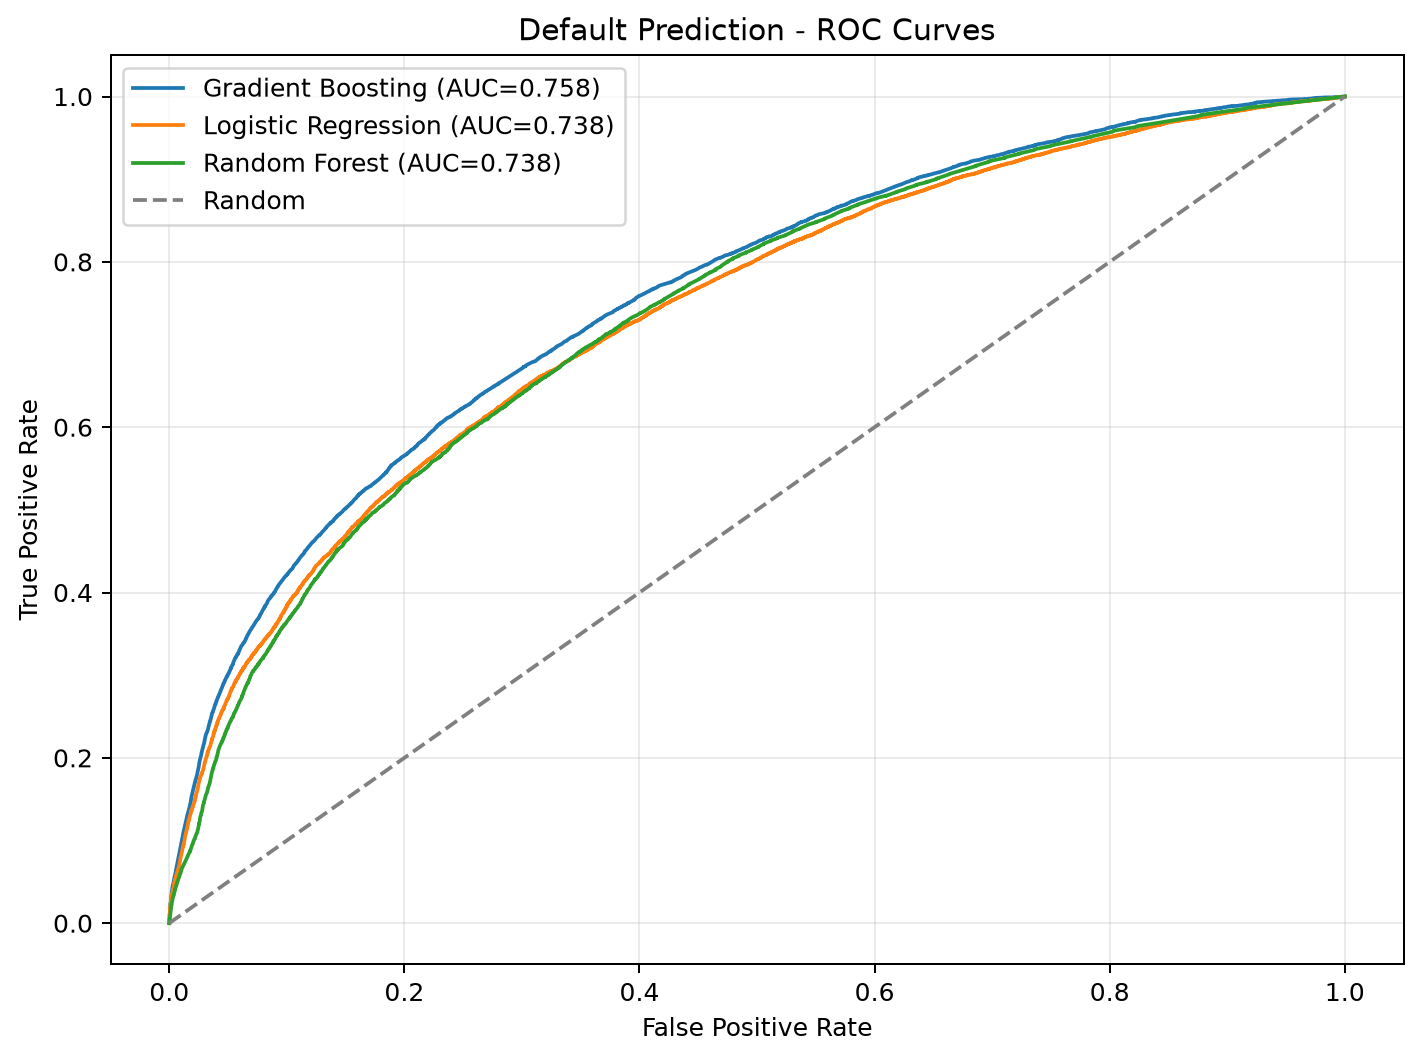

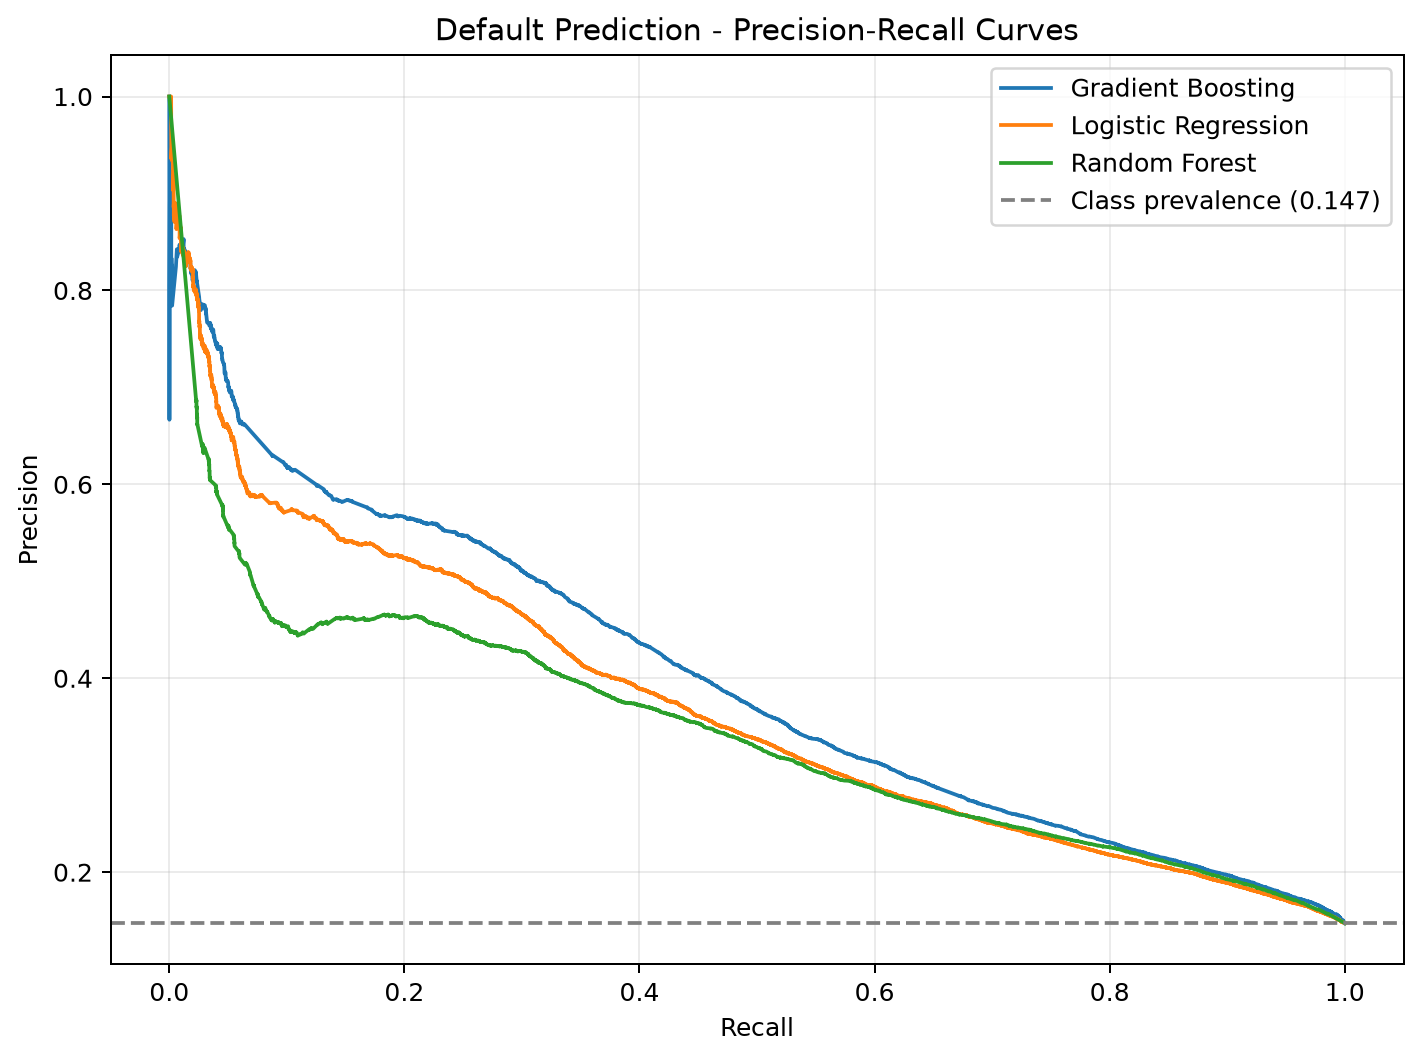

In [6]:
display(Image(filename=str(FIGURES_DIR / "roc_curve_comparison.png"), width=760))
display(
    Image(
        filename=str(FIGURES_DIR / "precision_recall_curve_comparison.png"),
        width=760,
    )
)

## Step 7 — Interpret the selected baseline

The saved pipeline is **Gradient Boosting**, selected by the predefined rule:
highest ROC-AUC, then highest recall in case of a tie. It is the best ranking
baseline in this experiment, but it is **not yet a production-ready model**.

,Measure,Value
0,ROC-AUC,75.80%
1,Precision for default,56.47%
2,Recall for default,20.39%
3,F1-score for default,29.96%


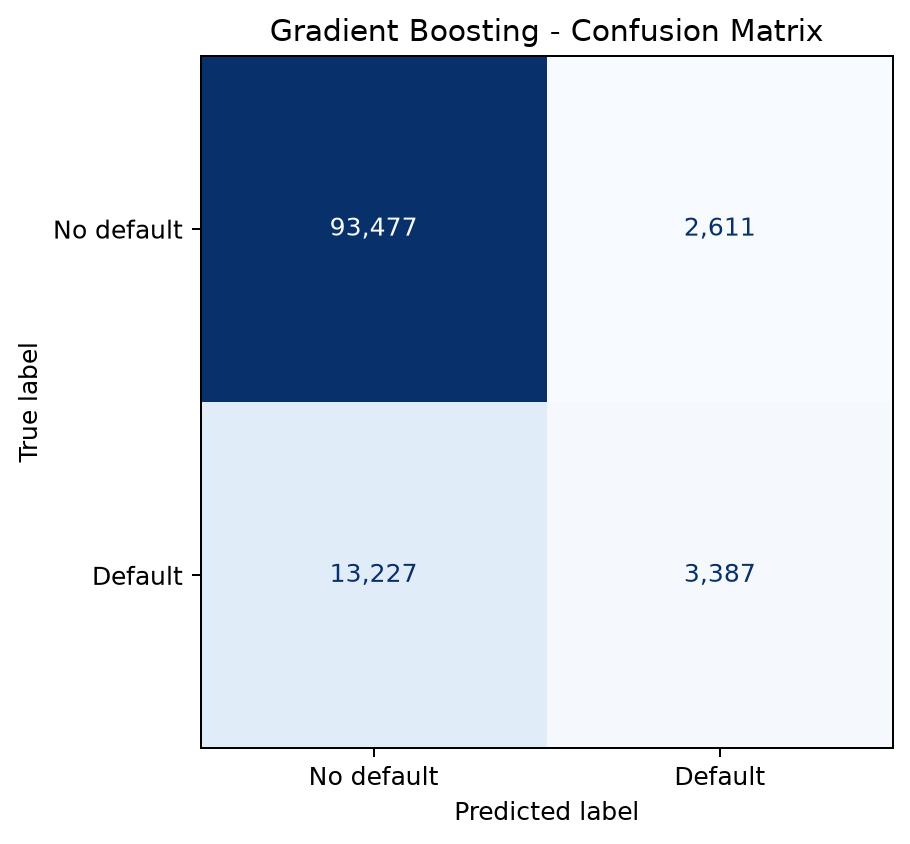


At the current **0.50 decision threshold**, the model correctly detects
**3,387** defaults but misses **13,227** defaults.
It also produces **2,611** false alerts and correctly recognises
**93,477** non-defaults.

The low recall (**20.39%**) is the main limitation.
The next modelling step must tune the decision threshold using the financial cost
of a missed default and the cost of reviewing or rejecting a safe borrower.
        

In [7]:
report_path = RESULTS_DIR / "classification_report_gradient_boosting.csv"
classification_report = pd.read_csv(report_path, index_col=0)

no_default_support = int(classification_report.loc["No default", "support"])
default_support = int(classification_report.loc["Default", "support"])
true_negatives = round(
    no_default_support * classification_report.loc["No default", "recall"]
)
true_positives = round(
    default_support * classification_report.loc["Default", "recall"]
)
false_positives = no_default_support - true_negatives
false_negatives = default_support - true_positives

selected_model_summary = pd.DataFrame(
    {
        "Measure": [
            "ROC-AUC",
            "Precision for default",
            "Recall for default",
            "F1-score for default",
        ],
        "Value": [
            gradient_metrics["roc_auc"],
            gradient_metrics["precision"],
            gradient_metrics["recall"],
            gradient_metrics["f1_score"],
        ],
    }
)

display(selected_model_summary.style.format({"Value": "{:.2%}"}))
display(
    Image(
        filename=str(FIGURES_DIR / "confusion_matrix_gradient_boosting.png"),
        width=560,
    )
)

display(
    Markdown(
        f'''
At the current **0.50 decision threshold**, the model correctly detects
**{true_positives:,}** defaults but misses **{false_negatives:,}** defaults.
It also produces **{false_positives:,}** false alerts and correctly recognises
**{true_negatives:,}** non-defaults.

The low recall (**{gradient_metrics['recall']:.2%}**) is the main limitation.
The next modelling step must tune the decision threshold using the financial cost
of a missed default and the cost of reviewing or rejecting a safe borrower.
        '''
    )
)

## Step 8 — Test decision thresholds

The default threshold of `0.50` is not automatically optimal. This exploratory
analysis tests thresholds from 5% to 90% on the current held-out test set and
selects the value that maximises the **F1-score**, which balances precision and
recall.

This produces a statistical recommendation for the progress report. It is not the
final banking threshold because no financial false-negative or false-positive costs
have been supplied. A final threshold must be selected on separate validation data,
preferably from a later time period.

,threshold,precision,recall,f1_score,true_positives,false_positives,false_negatives
Current threshold,50%,56.47%,20.39%,29.96%,"3,387","2,611","13,227"
Best F1 threshold,21%,39.41%,46.18%,42.53%,"7,673","11,797","8,941"


,threshold,precision,recall,f1_score
16,21%,39.41%,46.18%,42.53%
15,20%,37.94%,48.35%,42.52%
17,22%,40.41%,44.60%,42.40%
14,19%,36.63%,50.20%,42.35%
18,23%,41.36%,43.28%,42.30%
13,18%,35.63%,51.96%,42.27%
19,24%,42.67%,41.61%,42.13%
12,17%,34.24%,53.66%,41.81%
20,25%,44.07%,39.56%,41.70%
11,16%,32.59%,56.99%,41.46%


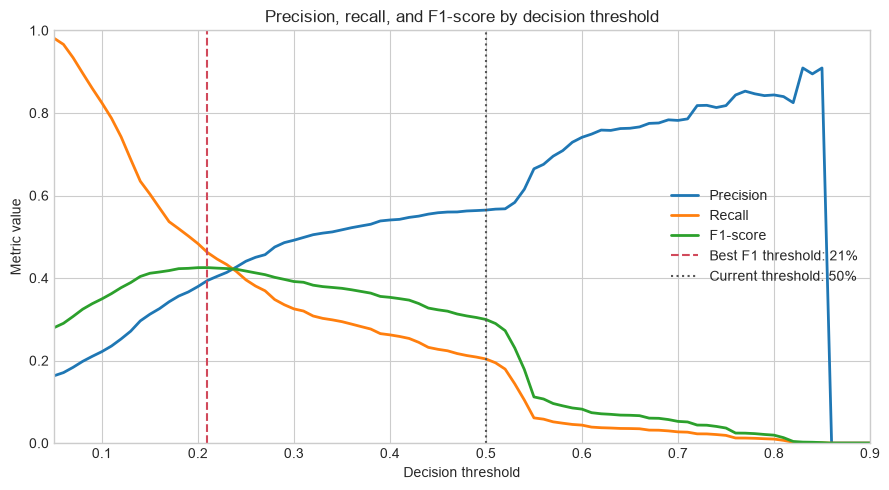


**Exploratory recommendation:** use a threshold of
**21%** when the statistical objective is to
maximise F1-score. At this threshold, precision is
**39.41%**, recall is
**46.18%**, and F1-score is
**42.53%**.

Compared with 50%, the model detects
**4,286**
additional defaults, while also creating
**9,186**
additional false alerts. This trade-off must be converted into financial cost
before adopting the threshold operationally.
        

In [8]:
THRESHOLD_SELECTION_METRIC = "f1_score"
THRESHOLDS_TO_TEST = np.round(np.arange(0.05, 0.91, 0.01), 2)

# Recreate the same deterministic test split used during model evaluation.
threshold_data = pd.read_csv(
    DATA_PATH,
    usecols=[*RAW_MODEL_FEATURES, TARGET_COLUMN],
    low_memory=False,
)
threshold_data = threshold_data[threshold_data[TARGET_COLUMN].notna()].copy()

threshold_features = threshold_data[RAW_MODEL_FEATURES]
threshold_target = threshold_data[TARGET_COLUMN].astype("int8")

_, threshold_test_features, _, threshold_test_target = train_test_split(
    threshold_features,
    threshold_target,
    test_size=0.20,
    random_state=metadata["random_state"],
    stratify=threshold_target,
)

threshold_model = load_best_pipeline(BEST_MODEL_PATH)
threshold_probabilities = threshold_model.predict_proba(
    threshold_test_features
)[:, 1]

threshold_records = []
for threshold in THRESHOLDS_TO_TEST:
    threshold_predictions = (threshold_probabilities >= threshold).astype("int8")
    tn, fp, fn, tp = confusion_matrix(
        threshold_test_target,
        threshold_predictions,
        labels=[0, 1],
    ).ravel()
    threshold_records.append(
        {
            "threshold": threshold,
            "precision": precision_score(
                threshold_test_target,
                threshold_predictions,
                zero_division=0,
            ),
            "recall": recall_score(
                threshold_test_target,
                threshold_predictions,
                zero_division=0,
            ),
            "f1_score": f1_score(
                threshold_test_target,
                threshold_predictions,
                zero_division=0,
            ),
            "true_positives": int(tp),
            "false_positives": int(fp),
            "false_negatives": int(fn),
            "true_negatives": int(tn),
        }
    )

threshold_results = pd.DataFrame(threshold_records)
best_threshold_row = threshold_results.loc[
    threshold_results[THRESHOLD_SELECTION_METRIC].idxmax()
]
current_threshold_row = threshold_results.loc[
    (threshold_results["threshold"] - 0.50).abs().idxmin()
]

threshold_comparison = pd.DataFrame(
    [current_threshold_row, best_threshold_row],
    index=["Current threshold", "Best F1 threshold"],
)
display(
    threshold_comparison[
        [
            "threshold",
            "precision",
            "recall",
            "f1_score",
            "true_positives",
            "false_positives",
            "false_negatives",
        ]
    ].style.format(
        {
            "threshold": "{:.0%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1_score": "{:.2%}",
            "true_positives": "{:,.0f}",
            "false_positives": "{:,.0f}",
            "false_negatives": "{:,.0f}",
        }
    )
)

top_thresholds = threshold_results.nlargest(10, THRESHOLD_SELECTION_METRIC)
display(
    top_thresholds[
        ["threshold", "precision", "recall", "f1_score"]
    ].style.format(
        {
            "threshold": "{:.0%}",
            "precision": "{:.2%}",
            "recall": "{:.2%}",
            "f1_score": "{:.2%}",
        }
    )
)

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(
    threshold_results["threshold"],
    threshold_results["precision"],
    label="Precision",
    linewidth=2,
)
ax.plot(
    threshold_results["threshold"],
    threshold_results["recall"],
    label="Recall",
    linewidth=2,
)
ax.plot(
    threshold_results["threshold"],
    threshold_results["f1_score"],
    label="F1-score",
    linewidth=2,
)
ax.axvline(
    best_threshold_row["threshold"],
    color="#D1495B",
    linestyle="--",
    label=f"Best F1 threshold: {best_threshold_row['threshold']:.0%}",
)
ax.axvline(
    0.50,
    color="#555555",
    linestyle=":",
    label="Current threshold: 50%",
)
ax.set(
    title="Precision, recall, and F1-score by decision threshold",
    xlabel="Decision threshold",
    ylabel="Metric value",
    xlim=(THRESHOLDS_TO_TEST.min(), THRESHOLDS_TO_TEST.max()),
    ylim=(0, 1),
)
ax.legend(loc="best")
plt.tight_layout()
plt.show()

display(
    Markdown(
        f'''
**Exploratory recommendation:** use a threshold of
**{best_threshold_row['threshold']:.0%}** when the statistical objective is to
maximise F1-score. At this threshold, precision is
**{best_threshold_row['precision']:.2%}**, recall is
**{best_threshold_row['recall']:.2%}**, and F1-score is
**{best_threshold_row['f1_score']:.2%}**.

Compared with 50%, the model detects
**{int(best_threshold_row['true_positives'] - current_threshold_row['true_positives']):,}**
additional defaults, while also creating
**{int(best_threshold_row['false_positives'] - current_threshold_row['false_positives']):,}**
additional false alerts. This trade-off must be converted into financial cost
before adopting the threshold operationally.
        '''
    )
)

## Step 9 — Understand what influences the model

Gradient Boosting feature importance shows which variables the fitted model used
most strongly. Importance describes model influence, **not causality**, and it does
not prove that a variable should be used in a final lending policy.

,Feature,Importance
0,initial_interest_rate,68.59%
1,country_Estonia,8.84%
2,loan_issue_year,8.60%
3,country_Spain,4.66%
4,issued_amount,3.26%
5,initial_loan_duration,1.53%
6,combined_income,1.12%
7,customer_risk_rating_AA,0.66%
8,customer_risk_rating_F,0.39%
9,country_Slovakia,0.38%


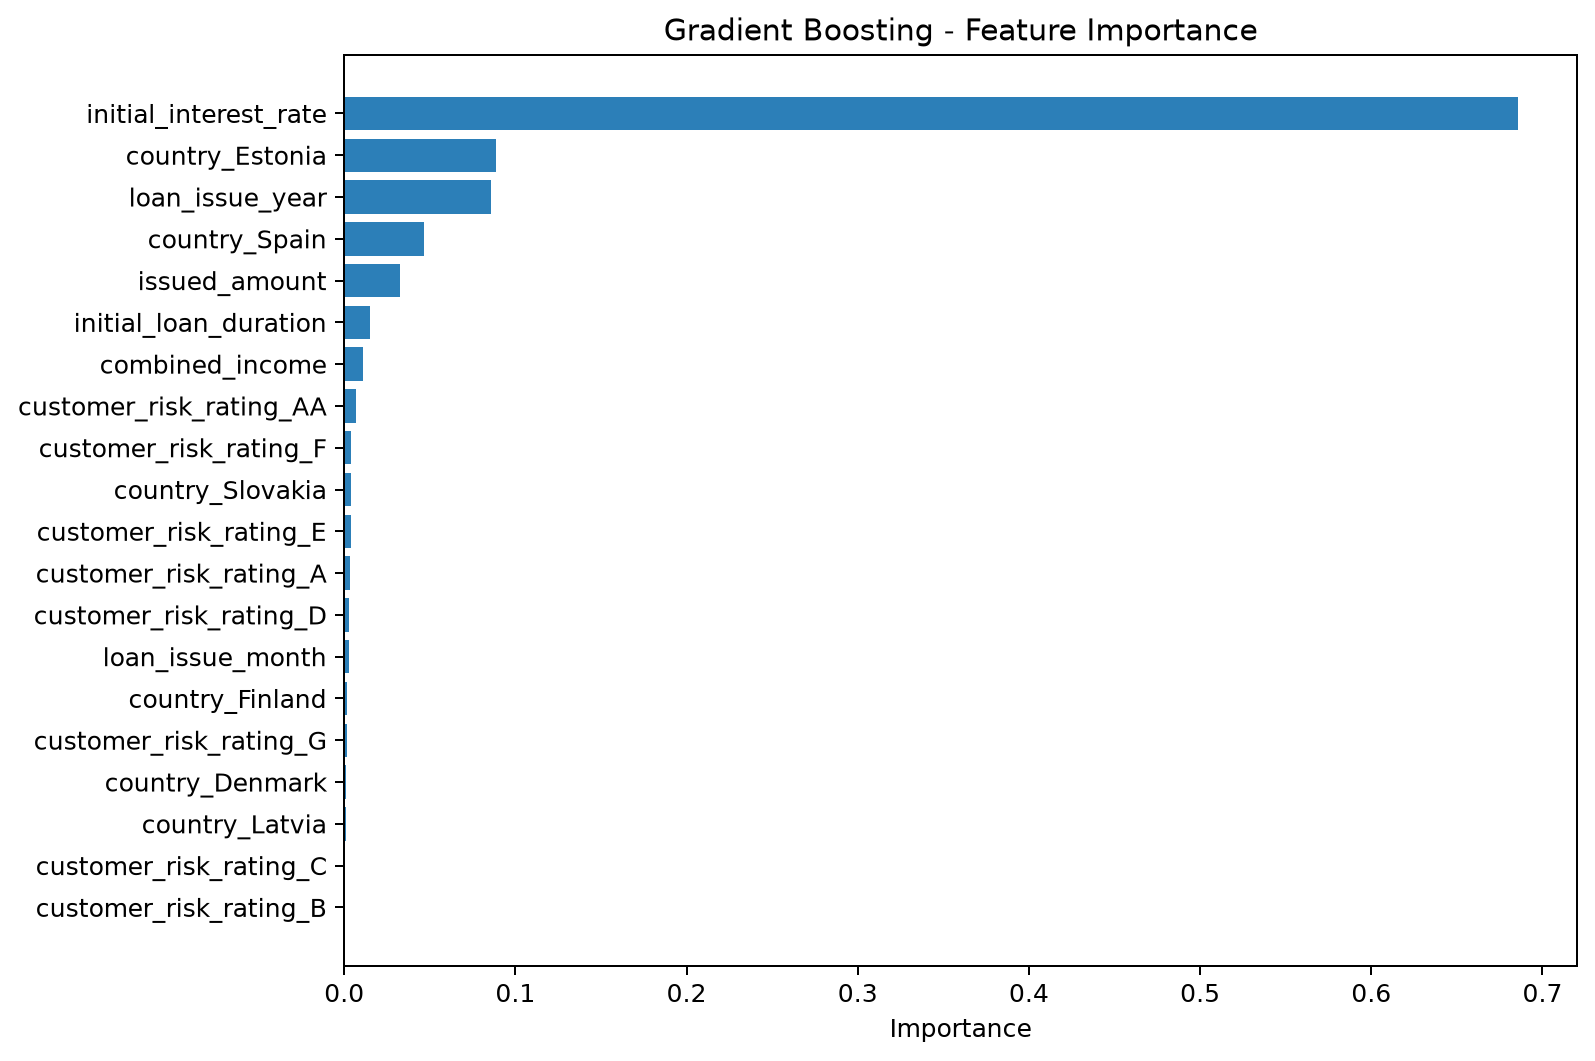

**Main observation:** `initial_interest_rate` is the most influential feature in this baseline (68.59% of the tree-based importance). This may partly reflect the institution's existing risk-based pricing policy, so it requires careful interpretation.

In [9]:
importance_path = RESULTS_DIR / "feature_importance_gradient_boosting.csv"
feature_importance = pd.read_csv(importance_path).head(10)

display(
    feature_importance[["feature", "importance"]]
    .rename(columns={"feature": "Feature", "importance": "Importance"})
    .style.format({"Importance": "{:.2%}"})
)
display(
    Image(
        filename=str(FIGURES_DIR / "feature_importance_gradient_boosting.png"),
        width=760,
    )
)

top_feature = feature_importance.iloc[0]
display(
    Markdown(
        f"**Main observation:** `{top_feature['feature']}` is the most influential "
        f"feature in this baseline ({top_feature['importance']:.2%} of the tree-based "
        "importance). This may partly reflect the institution's existing risk-based "
        "pricing policy, so it requires careful interpretation."
    )
)

## Step 10 — Demonstrate individual risk predictions

The saved pipeline accepts the seven raw origination fields and returns a default
probability. The reporting bands currently use these simple thresholds:

- **Low risk:** probability below 30%;
- **Medium risk:** probability from 30% to below 60%;
- **High risk:** probability of 60% or more.

The binary class still uses the standard 50% threshold. Therefore, a medium-risk
loan can have predicted class 0 or 1. These bands are provisional dashboard labels,
not an approved credit policy. The probabilities have not yet been calibrated, so
a score of 60% must not yet be interpreted as a verified 60% observed default rate.

In [10]:
def evenly_spaced_rows(data: pd.DataFrame, number: int) -> pd.DataFrame:
    '''Select rows across the probability range without random variation.'''
    if data.empty:
        return data
    ordered = data.sort_values("probability_of_default")
    positions = np.linspace(0, len(ordered) - 1, min(number, len(ordered)))
    return ordered.iloc[np.unique(positions.round().astype(int))]


def select_diverse_examples(data: pd.DataFrame, number: int = 4) -> pd.DataFrame:
    '''Include known and missing income examples when both are available.'''
    known_income = data[data["combined_income"].notna()]
    missing_income = data[data["combined_income"].isna()]

    if known_income.empty or missing_income.empty:
        return evenly_spaced_rows(data, number)

    known_examples = evenly_spaced_rows(known_income, number // 2)
    missing_examples = evenly_spaced_rows(missing_income, number - number // 2)
    return pd.concat([known_examples, missing_examples]).sort_values(
        "probability_of_default"
    )


candidate_loans = pd.read_csv(
    DATA_PATH,
    usecols=RAW_MODEL_FEATURES,
    low_memory=False,
)
candidate_predictions = predict_default_risk(candidate_loans, BEST_MODEL_PATH)
scored_portfolio = pd.concat([candidate_loans, candidate_predictions], axis=1)

risk_order = ["Low risk", "Medium risk", "High risk"]
risk_distribution = (
    scored_portfolio["risk_category"]
    .value_counts()
    .reindex(risk_order, fill_value=0)
    .rename_axis("Risk category")
    .reset_index(name="Loans")
)
risk_distribution["Share"] = risk_distribution["Loans"] / len(scored_portfolio)
display(
    risk_distribution.style.format(
        {
            "Loans": "{:,.0f}",
            "Share": "{:.2%}",
        }
    )
)

input_quality = (
    scored_portfolio.groupby("risk_category", observed=True)
    .agg(
        loans=("risk_category", "size"),
        missing_income=("combined_income", lambda values: values.isna().sum()),
        missing_risk_rating=(
            "customer_risk_rating",
            lambda values: values.isna().sum(),
        ),
    )
    .reindex(risk_order)
)
input_quality["Missing income"] = (
    input_quality["missing_income"] / input_quality["loans"]
)
input_quality["Missing risk rating"] = (
    input_quality["missing_risk_rating"] / input_quality["loans"]
)
display(
    input_quality[["Missing income", "Missing risk rating"]]
    .rename_axis("Risk category")
    .style.format("{:.2%}")
)

example_groups = []
example_labels = []
for risk_category in risk_order:
    category_data = scored_portfolio[
        scored_portfolio["risk_category"] == risk_category
    ]
    selected = select_diverse_examples(category_data, number=4)
    if not selected.empty:
        example_groups.append(selected)
        example_labels.append(risk_category)

diverse_examples = pd.concat(example_groups, keys=example_labels)
display_columns = [
    "country",
    "loan_issued_at",
    "issued_amount",
    "initial_interest_rate",
    "initial_loan_duration",
    "combined_income",
    "customer_risk_rating",
    "probability_of_default",
    "predicted_class",
]
formatted_examples = diverse_examples[display_columns].copy()
formatted_examples["issued_amount"] = formatted_examples["issued_amount"].map(
    lambda value: "Missing" if pd.isna(value) else f"€{value:,.2f}"
)
formatted_examples["combined_income"] = formatted_examples["combined_income"].map(
    lambda value: "Missing" if pd.isna(value) else f"€{value:,.2f}"
)
formatted_examples["initial_interest_rate"] = formatted_examples[
    "initial_interest_rate"
].map(lambda value: "Missing" if pd.isna(value) else f"{value:.2%}")
formatted_examples["probability_of_default"] = formatted_examples[
    "probability_of_default"
].map(lambda value: f"{value:.2%}")
formatted_examples["customer_risk_rating"] = formatted_examples[
    "customer_risk_rating"
].fillna("Missing")
formatted_examples.index.names = ["Risk category", "Record index"]

display(formatted_examples)

,Risk category,Loans,Share
0,Low risk,"680,078",92.17%
1,Medium risk,"52,911",7.17%
2,High risk,"4,900",0.66%


,Missing income,Missing risk rating
Risk category,,
Low risk,32.77%,42.26%
Medium risk,85.76%,89.46%
High risk,99.78%,99.78%


country           loan_issued_at  \
Risk category Record index                                         
Low risk      342399        Netherlands  2025-11-06 13:42:12.300   
              316718            Estonia  2015-03-11 03:15:11.000   
              427696            Finland  2015-12-31 12:42:33.000   
              106662             Latvia  2025-07-07 11:53:59.887   
Medium risk   698524            Denmark  2026-01-09 13:33:12.667   
              358291              Spain  2015-07-30 20:06:27.000   
              33277             Denmark  2026-03-25 18:47:33.520   
              312613           Slovakia  2014-06-10 10:01:17.000   
High risk     716566              Spain  2016-12-23 20:14:00.000   
              18767             Denmark  2026-03-26 16:16:53.663   
              532841            Denmark  2026-03-29 19:39:23.487   
              284382              Spain  2017-08-25 00:02:50.000   

                           issued_amount initial_interest_rate  \
Risk category Record index                                       
Low risk      342399             €104.00                 7.20%   
              316718             €700.00                14.75%   
              427696           €2,335.00                40.16%   
              106662           €3,780.00                30.90%   
Medium risk   698524           €1,470.38                18.81%   
              358291           €1,790.00                31.12%   
              33277              €690.35                20.89%   
              312613           €1,900.00                26.00%   
High risk     716566             €530.00                97.18%   
              18767            €1,035.52                20.89%   
              532841           €1,035.52                20.89%   
              284382             €432.00               179.16%   

                            initial_loan_duration combined_income  \
Risk category Record index                                          
Low risk      342399                           24       €6,148.44   
              316718                            1         Missing   
              427696                           60         Missing   
              106662                           60       €1,316.96   
Medium risk   698524                           42       €2,031.90   
              358291                           36         Missing   
              33277                            60       €1,889.28   
              312613                           48         Missing   
High risk     716566                            6         Missing   
              18767                            60       €2,978.02   
              532841                           60       €1,692.63   
              284382                           36         Missing   

                           customer_risk_rating probability_of_default  \
Risk category Record index                                               
Low risk      342399                         AA                  1.66%   
              316718                    Missing                  2.68%   
              427696                    Missing                 29.99%   
              106662                          A                 29.99%   
Medium risk   698524                          B                 30.00%   
              358291                    Missing                 30.01%   
              33277                           D                 59.60%   
              312613                    Missing                 59.99%   
High risk     716566                    Missing                 60.01%   
              18767                           D                 60.50%   
              532841                          D                 66.52%   
              284382                    Missing                 85.65%   

                            predicted_class  
Risk category Record index                   
Low risk      342399                      0  
            

### Important note about missing income

`Missing` means that the historical dataset did not provide a value; it does not
mean that the borrower's income was zero. The current pipeline replaces missing
income with the training-set median before prediction. Consequently, high-risk
examples with missing income are also being scored from their other inputs, such
as interest rate, country, issuance period, amount, and duration.

Before deployment, the next experiment should add explicit missing-value indicators
and test whether they improve out-of-time performance without creating an unstable
shortcut. The concentration of missing fields in some risk bands may reflect older
data-collection practices or historical cohorts; it does **not** prove that missing
income causes default.

## Step 11 — Conclusion and next steps

### What has been completed

- A leakage-safe binary target and origination-time feature set were defined.
- Logistic Regression, Random Forest, and Gradient Boosting were evaluated on the
  same untouched test set.
- The complete preprocessing and Gradient Boosting pipeline was saved for reuse.
- The pipeline can produce individual probabilities and portfolio risk bands.

### Current conclusion

Gradient Boosting achieved the highest overall discriminative performance, with a **ROC-AUC of 75.80%**, indicating the strongest ability to distinguish between defaulted and non-defaulted borrowers among the evaluated models. Using the default **50% decision threshold**, the model achieved high precision (**56.47%**) but a low recall (**20.39%**), meaning that many defaulted loans were missed. After optimizing the classification threshold to **21%**, recall increased substantially to **46.18%**, while the **F1-score improved from 29.96% to 42.53%**. Although this reduced precision to **39.41%**, it provided a significantly better balance between identifying risky borrowers and limiting false alarms, making the model more suitable for credit risk screening.

This baseline provides a solid foundation for the internship project, although several improvements remain. The current evaluation uses a random train-test split rather than a time-based validation strategy, probability scores are not yet calibrated, and missing values for income and customer risk rating are concentrated in older observations. In addition, the use of variables such as country and customer risk rating should be carefully reviewed from both governance and fairness perspectives before deployment in a real-world credit decision system.


### Next work

1. Select a decision threshold from financial false-negative and false-positive costs.
2. Validate on a later time period and calibrate the predicted probabilities.
3. Test missingness indicators, balanced boosting, controlled tuning, and explainability.
4. Define whether scoring occurs before approval or at final loan origination.
5. Complete fairness checks, then export validated scores to the Power BI dashboard.